# Notebook 07: Problem 3 — Econometric Drivers & Statistical Inference
**Project:** Exploratory Data Analysis of Air Pollution in Indian Cities
**Course:** IT 462 — Exploratory Data Analysis | Autumn Semester
**Mentor:** Dr. Gopinath Panda

**Research Question:** How do meteorological conditions, festivals, crop-burning activity, and city-specific characteristics relate to PM2.5 concentrations?

This notebook implements:
1. Non-parametric hypothesis testing (Diwali Mann-Whitney U, Seasonal Kruskal-Wallis, Weekend effect).
2. Econometric OLS with city fixed effects and cluster-robust standard errors.
3. Residual diagnostics (Durbin-Watson, Breusch-Pagan, Normal Q-Q plot).
4. Supervised predictive regression benchmark vs. city-mean baseline.

In [1]:
import os, sys
import pandas as pd
from IPython.display import Image, display
from pathlib import Path

PROJECT_ROOT = Path(".").resolve().parents[0] if Path(".").resolve().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import TABLES_DIR, FIGURES_DIR

## 1. Non-Parametric Hypothesis Tests

In [2]:
df_hyp = pd.read_csv(TABLES_DIR / "problem3_hypothesis_tests.csv")
df_hyp

,Hypothesis,Test,Statistic,p_value,Group_1_Median,Group_2_Median,Conclusion
0,Diwali Window PM2.5 > Baseline Non-Festival,Mann-Whitney U (One-Sided),249863.50,2.533900e-12,60.44,36.41,Reject H0 (Statistically Significant Surge)
1,Seasonal Divergence Across Annual Cycle,Kruskal-Wallis H-Test,1672.03,0.000000e+00,59.32,22.41,Reject H0 (Highly Significant Seasonality)
2,Weekend Effect (Anthropogenic Traffic Lull),Mann-Whitney U (Two-Sided),1871506.00,6.771200e-01,36.90,36.79,Fail to Reject H0 (No Significant Weekend Drop)


## 2. Econometric Regression Coefficients & 95% Clustered CIs

In [3]:
df_coef = pd.read_csv(TABLES_DIR / "problem3_econometric_coefficients.csv", index_col=0)
df_coef.loc[~df_coef.index.str.startswith("C(city)")]

,Coefficient,Std_Error_Clustered,t_statistic,p_value,CI_Lower_95,CI_Upper_95
Intercept,38.683816,9.059530,4.269958,1.955094e-05,20.927464,56.440168
temp_mean,-0.866173,0.220848,-3.922033,8.780502e-05,-1.299027,-0.433319
humidity_mean,-0.075856,0.037905,-2.001199,4.537091e-02,-0.150150,-0.001563
wind_speed_mean,-0.782882,0.240793,-3.251260,1.148946e-03,-1.254829,-0.310936
precip_sum,-0.049902,0.026186,-1.905651,5.669550e-02,-0.101227,0.001422
boundary_layer_height_mean,0.006941,0.001832,3.788761,1.514006e-04,0.003350,0.010532
diwali_window,4.803332,1.149993,4.176835,2.955933e-05,2.549387,7.057277
fire_count_NW_lag_1,0.000616,0.000828,0.743498,4.571801e-01,-0.001008,0.002239
pm25_lag_1,0.824627,0.028811,28.621921,3.585663e-180,0.768158,0.881096


## 3. Supervised Predictive Regression Benchmark

In [4]:
df_reg = pd.read_csv(TABLES_DIR / "problem3_regression_comparison.csv")
df_reg

,Model,RMSE (µg/m³),MAE (µg/m³),R_Squared,Beats_Baseline
0,City-Mean Baseline,48.08,29.55,-0.106,Baseline
1,Ridge Regression (L2),15.63,8.90,0.883,Yes
2,Lasso Regression (L1),15.87,8.92,0.879,Yes
3,Random Forest Regressor,20.01,10.30,0.808,Yes
4,HistGradientBoosting Regressor,20.60,10.69,0.797,Yes


## 4. Coefficient Forest Plot (Fig 17) & Residual Diagnostics (Fig 18)

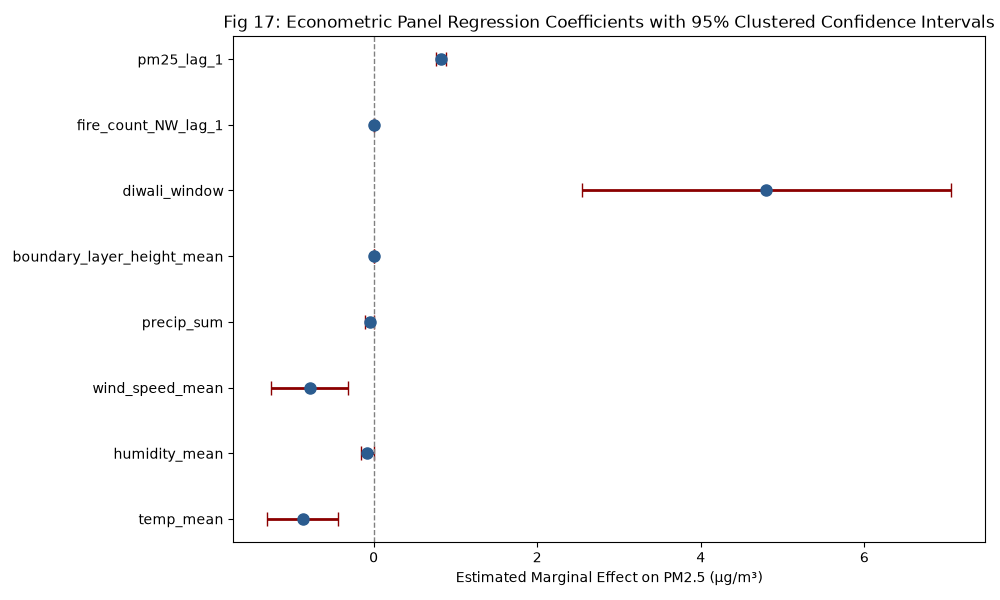

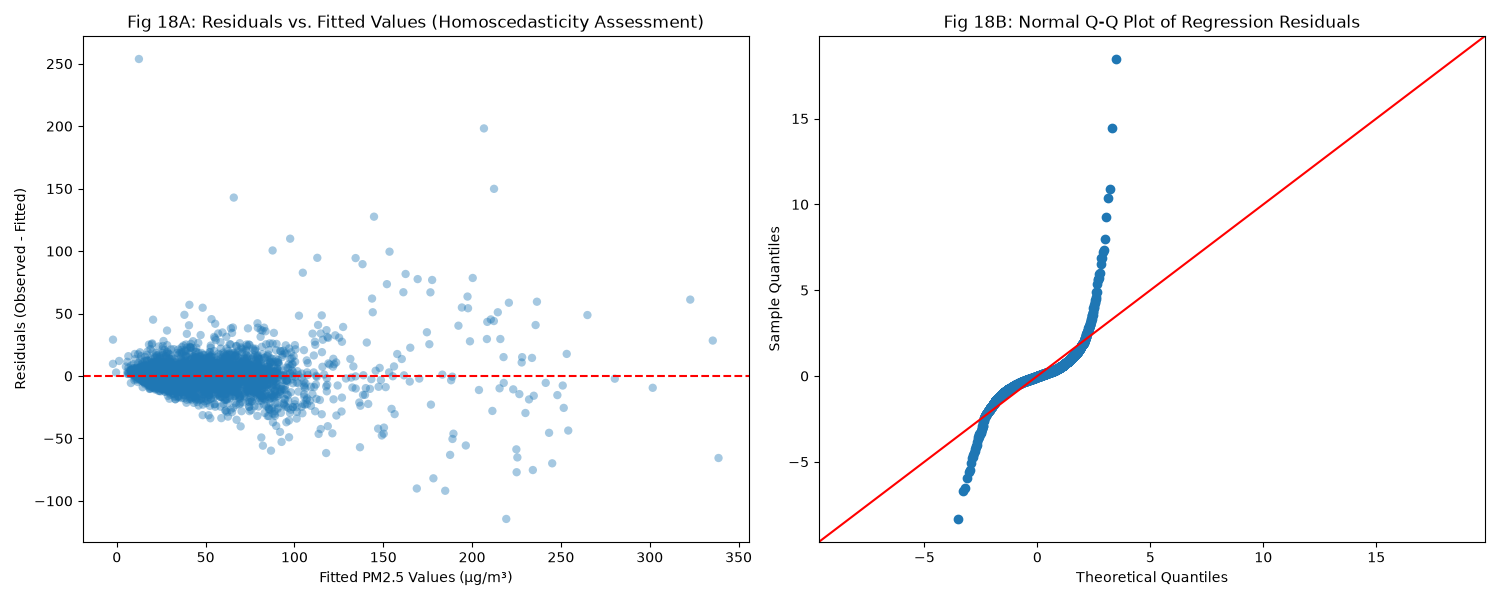

In [5]:
display(Image(filename=str(FIGURES_DIR / "fig17_coefficients_forest_plot.png")))
display(Image(filename=str(FIGURES_DIR / "fig18_regression_diagnostics.png")))